Dataset Shape: (50000, 2)
Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 49ms/step - accuracy: 0.5306 - loss: 0.6859 - val_accuracy: 0.5695 - val_loss: 0.6694
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.5884 - loss: 0.6538 - val_accuracy: 0.5615 - val_loss: 0.6625
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.6609 - loss: 0.5605 - val_accuracy: 0.7509 - val_loss: 0.5484
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.6838 - loss: 0.5401 - val_accuracy: 0.5411 - val_loss: 0.7145
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.7329 - loss: 0.4651 - val_accuracy: 0.6625 - val_loss: 0.6764
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6552 - loss: 0.6842
Test Accuracy: 65.52 %


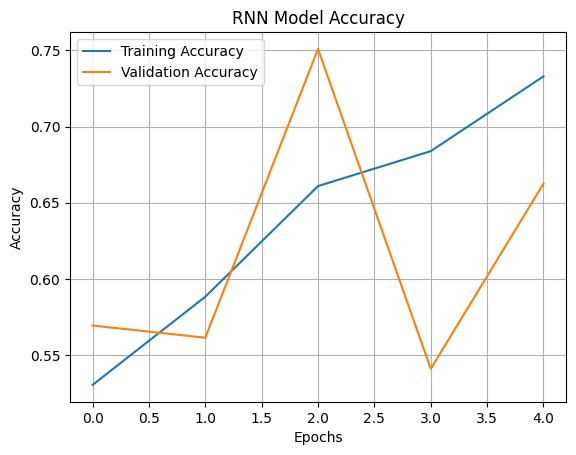

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step

Actual vs Predicted Sentiment

Review: 1
Actual Sentiment: Positive
Predicted Sentiment: Positive

Review: 2
Actual Sentiment: Positive
Predicted Sentiment: Negative

Review: 3
Actual Sentiment: Negative
Predicted Sentiment: Negative

Review: 4
Actual Sentiment: Positive
Predicted Sentiment: Positive

Review: 5
Actual Sentiment: Negative
Predicted Sentiment: Negative


In [2]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from sklearn.model_selection import train_test_split

# Step 2: Load IMDB Dataset
data = pd.read_csv("IMDB_Dataset.csv")

print("Dataset Shape:", data.shape)

# Step 3: Prepare Data
X = data['review'].astype(str)
y = data['sentiment'].map({'positive': 1, 'negative': 0})

# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 5: Tokenization and Padding
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

X_train = pad_sequences(X_train, maxlen=200, padding='post')
X_test = pad_sequences(X_test, maxlen=200, padding='post')

# Step 6: Build RNN Model
model = Sequential([
    Embedding(10000, 32),
    SimpleRNN(32),
    Dense(1, activation='sigmoid')
])

# Step 7: Compile Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Step 8: Train Model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

# Step 9: Evaluate Model
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Step 10: Plot Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("RNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Step 11: Example Predictions
predictions = model.predict(X_test[:5])

print("\nActual vs Predicted Sentiment")

for i in range(5):
    actual = "Positive" if y_test.iloc[i] == 1 else "Negative"
    predicted = "Positive" if predictions[i][0] >= 0.5 else "Negative"

    print("\nReview:", i + 1)
    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", predicted)